In [1]:
import pandas as pd

wine_df = pd.read_csv("winemag-data-130k-v2.csv", index_col=0)
wine_df["title"].head(10)

0                    Nicosia 2013 Vulkà Bianco  (Etna)
1        Quinta dos Avidagos 2011 Avidagos Red (Douro)
2        Rainstorm 2013 Pinot Gris (Willamette Valley)
3    St. Julian 2013 Reserve Late Harvest Riesling ...
4    Sweet Cheeks 2012 Vintner's Reserve Wild Child...
5    Tandem 2011 Ars In Vitro Tempranillo-Merlot (N...
6     Terre di Giurfo 2013 Belsito Frappato (Vittoria)
7                Trimbach 2012 Gewurztraminer (Alsace)
8    Heinz Eifel 2013 Shine Gewürztraminer (Rheinhe...
9    Jean-Baptiste Adam 2012 Les Natures Pinot Gris...
Name: title, dtype: object

In [2]:
wine_df["wine vintage"] = (
    wine_df["title"]
    .str.extract(r"\b((?:19|20)\d{2})\b", expand=False)
    .astype("Int64")
)

wine_df[["title", "wine vintage"]].head(10)

,title,wine vintage
0,Nicosia 2013 Vulkà Bianco (Etna),2013
1,Quinta dos Avidagos 2011 Avidagos Red (Douro),2011
2,Rainstorm 2013 Pinot Gris (Willamette Valley),2013
3,St. Julian 2013 Reserve Late Harvest Riesling ...,2013
4,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,2012
5,Tandem 2011 Ars In Vitro Tempranillo-Merlot (N...,2011
6,Terre di Giurfo 2013 Belsito Frappato (Vittoria),2013
7,Trimbach 2012 Gewurztraminer (Alsace),2012
8,Heinz Eifel 2013 Shine Gewürztraminer (Rheinhe...,2013
9,Jean-Baptiste Adam 2012 Les Natures Pinot Gris...,2012


In [3]:
print(wine_df["wine vintage"].value_counts().sort_index().to_string())

wine vintage
1904        1
1912        8
1919        1
1927        2
1929        6
1934        1
1935        1
1941        1
1945        1
1947        1
1952        2
1957        1
1961        1
1963        3
1964        2
1965        1
1966        2
1967        1
1968        1
1969        1
1973        1
1974        1
1976        1
1978        2
1980        2
1982        1
1983        2
1984        2
1985        4
1986        4
1987        2
1988        5
1989        6
1990        5
1991        4
1992       16
1993        3
1994       23
1995       50
1996       67
1997      303
1998      551
1999      641
2000      758
2001      691
2002      366
2003      598
2004     1774
2005     3613
2006     5772
2007     7053
2008     7439
2009     9875
2010    12165
2011    12552
2012    15746
2013    15874
2014    15582
2015    10051
2016     3691
2017       11


In [4]:
number_of_origins = wine_df["country"].nunique()
print(f"Number of origins: {number_of_origins}")

Number of origins: 43


In [5]:
origin_counts = wine_df["country"].value_counts()
print(origin_counts.to_string())

country
US                        54504
France                    22093
Italy                     19540
Spain                      6645
Portugal                   5691
Chile                      4472
Argentina                  3800
Austria                    3345
Australia                  2329
Germany                    2165
New Zealand                1419
South Africa               1401
Israel                      505
Greece                      466
Canada                      257
Hungary                     146
Bulgaria                    141
Romania                     120
Uruguay                     109
Turkey                       90
Slovenia                     87
Georgia                      86
England                      74
Croatia                      73
Mexico                       70
Moldova                      59
Brazil                       52
Lebanon                      35
Morocco                      28
Peru                         16
Ukraine                      14


In [6]:
print(f"Number of provinces: {wine_df['province'].nunique()}")
print(wine_df["province"].value_counts().to_string())

Number of provinces: 425
province
California                         36247
Washington                          8639
Bordeaux                            5941
Tuscany                             5897
Oregon                              5373
Burgundy                            3980
Northern Spain                      3851
Piedmont                            3729
Mendoza Province                    3264
Veneto                              2716
New York                            2688
Alsace                              2440
Northeastern Italy                  2138
Loire Valley                        1856
Sicily & Sardinia                   1797
Champagne                           1613
Southwest France                    1503
South Australia                     1349
Southern Italy                      1349
Provence                            1346
Douro                               1281
Central Italy                       1233
Catalonia                           1164
Rhône Valley           

In [7]:
print(f"Number of regions: {wine_df['region_1'].nunique()}")
print(wine_df["region_1"].value_counts().to_string())

Number of regions: 1229
region_1
Napa Valley                                           4480
Columbia Valley (WA)                                  4124
Russian River Valley                                  3091
California                                            2629
Paso Robles                                           2350
Mendoza                                               2301
Willamette Valley                                     2301
Alsace                                                2163
Champagne                                             1613
Barolo                                                1599
Finger Lakes                                          1565
Sonoma Coast                                          1474
Brunello di Montalcino                                1470
Rioja                                                 1469
Sonoma County                                         1246
Toscana                                               1197
Walla Walla Valley (WA)

## Expanded Napa baseline: 2005–2015 vintage classification

This extends the earlier 2011–2014 task to eleven vintage classes, using the same metadata-only logistic regression baseline and description + metadata model family. Only variety and subregion enter the metadata model; vintage is the target, not an input.

Use Napa wines, drop missing title/vintage, and keep one review per title. Preserve the original 2011–2014 training/test membership and stratify additional years into 80/20 training/test partitions. Missing metadata becomes `Unknown`. Preprocessing is fitted only on training folds.

Report macro F1, accuracy, per-year recall, class counts, and the majority reference. Eleven-class accuracy is not directly comparable to four-class accuracy. The original four-year holdout was previously viewed; this remains exploratory rather than wholly independent final validation.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

selected_vintages = list(range(2005, 2016))
napa_model_data = (
    wine_df.loc[
        wine_df["region_2"].eq("Napa")
        & wine_df["wine vintage"].isin(selected_vintages),
        ["title", "wine vintage", "variety", "region_1"]
    ]
    .dropna(subset=["title", "wine vintage"])
    .drop_duplicates(subset="title")
    .copy()
)
features = ["variety", "region_1"]
X = napa_model_data[features].astype("string").fillna("Unknown").astype(str)
y = napa_model_data["wine vintage"].astype(int)
# Preserve the original four-year partition; add other years separately.
original_mask = y.isin([2011, 2012, 2013, 2014])
old_train, old_test = train_test_split(
    y.loc[original_mask].index, test_size=0.20, random_state=42,
    stratify=y.loc[original_mask]
)
new_train, new_test = train_test_split(
    y.loc[~original_mask].index, test_size=0.20, random_state=42,
    stratify=y.loc[~original_mask]
)
train_indices = list(old_train) + list(new_train)
test_indices = list(old_test) + list(new_test)
X_train, X_test = X.loc[train_indices], X.loc[test_indices]
y_train, y_test = y.loc[train_indices], y.loc[test_indices]
assert y_train.value_counts().min() >= 5
print("Wine counts by vintage:")
print(y.value_counts().sort_index().to_string())
print(f"\nTraining wines: {len(X_train):,}; test wines: {len(X_test):,}")

Wine counts by vintage:
wine vintage
2005    344
2006    355
2007    476
2008    505
2009    683
2010    659
2011    469
2012    893
2013    834
2014    446
2015    131

Training wines: 4,635; test wines: 1,160


In [9]:
# Established baseline: simple linear classification using metadata.
baseline_model = Pipeline([
    ("categories", OneHotEncoder(handle_unknown="ignore")),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
])
baseline_model.fit(X_train, y_train)
predicted_vintages = baseline_model.predict(X_test)

# Reference benchmark: always predict the most frequent training vintage.
majority_model = DummyClassifier(strategy="most_frequent")
majority_model.fit(X_train, y_train)
majority_predictions = majority_model.predict(X_test)

results = []
for name, predictions in [
    ("Majority-class reference", majority_predictions),
    ("Established metadata baseline", predicted_vintages),
]:
    results.append({
        "Model": name,
        "Test accuracy": accuracy_score(y_test, predictions),
        "Test macro F1": f1_score(y_test, predictions, average="macro", zero_division=0),
    })
print(pd.DataFrame(results).set_index("Model").round(3).to_string())
print("\nPer-vintage performance (metadata baseline):")
print(classification_report(y_test, predicted_vintages, labels=selected_vintages, zero_division=0))

# Verify that no wine title appears in both sets.
assert set(napa_model_data.loc[X_train.index, "title"]).isdisjoint(
    napa_model_data.loc[X_test.index, "title"]
)

                               Test accuracy  Test macro F1
Model                                                      
Majority-class reference               0.154          0.024
Established metadata baseline          0.152          0.084

Per-vintage performance (metadata baseline):
              precision    recall  f1-score   support

        2005       0.00      0.00      0.00        69
        2006       0.33      0.01      0.03        71
        2007       0.12      0.12      0.12        95
        2008       0.00      0.00      0.00       101
        2009       0.09      0.04      0.05       137
        2010       0.18      0.05      0.08       132
        2011       0.00      0.00      0.00        94
        2012       0.16      0.60      0.25       179
        2013       0.16      0.21      0.18       167
        2014       0.11      0.09      0.10        89
        2015       0.20      0.08      0.11        26

    accuracy                           0.15      1160
   macro a

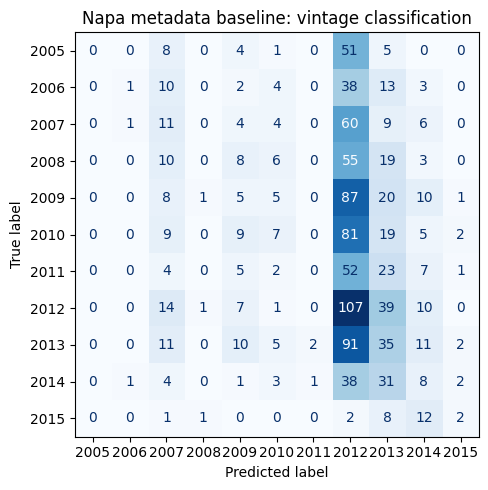

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, predicted_vintages, labels=selected_vintages,
    cmap="Blues", colorbar=False, ax=ax
)
ax.set_title("Napa metadata baseline: vintage classification")
plt.tight_layout()
plt.show()

## Bias–variance check before adding descriptions

Use only the existing training partition for five-fold stratified cross-validation. Each fold fits a fresh preprocessing pipeline, so validation rows do not influence category encoding. Report training and validation accuracy and macro F1, plus a majority-class reference on the same folds. Fold standard deviations describe variation across these splits; they are not confidence intervals or a formal bias–variance decomposition.

The learning curve varies the amount of training data within each fold while keeping validation folds fixed. The existing test partition is not used in these diagnostics or to choose changes. Since its results have already been viewed, it is not a pristine final holdout for extensive later experimentation.

Low training and validation performance suggests limited predictive signal or underfitting. A large training–validation gap suggests overfitting. Improving validation performance as training size grows suggests more data may help. These patterns guide the next experiment; they do not by themselves prove a cause.

In [11]:
from sklearn.model_selection import StratifiedKFold, cross_validate, learning_curve
from sklearn.base import clone
import numpy as np

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"accuracy": "accuracy", "macro_f1": "f1_macro"}
diagnostic_rows = []
for name, estimator in [
    ("Metadata baseline", baseline_model),
    ("Majority-class reference", DummyClassifier(strategy="most_frequent")),
]:
    scores = cross_validate(
        clone(estimator), X_train, y_train, cv=cv, scoring=scoring,
        return_train_score=True, error_score="raise"
    )
    for metric in scoring:
        train = scores[f"train_{metric}"]
        validation = scores[f"test_{metric}"]
        diagnostic_rows.append({
            "Model": name,
            "Metric": metric,
            "Train mean": train.mean(),
            "Validation mean": validation.mean(),
            "Validation SD": validation.std(ddof=1),
            "Train-validation gap": train.mean() - validation.mean(),
        })
diagnostic_results = pd.DataFrame(diagnostic_rows)
print(diagnostic_results.round(3).to_string(index=False))

# Each point uses a fraction of each CV fold's training rows.
# Shuffle rows before subsampling to avoid relying on input order.
curve_sizes, curve_train, curve_validation = learning_curve(
    clone(baseline_model), X_train, y_train, cv=cv,
    train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0], scoring="f1_macro",
    shuffle=True, random_state=42, error_score="raise"
)
learning_curve_results = pd.DataFrame({
    "Training wines per fold": curve_sizes,
    "Train macro F1": curve_train.mean(axis=1),
    "Validation macro F1": curve_validation.mean(axis=1),
    "Validation SD": curve_validation.std(axis=1, ddof=1),
})
print("\nLearning curve (training partition only):")
print(learning_curve_results.round(3).to_string(index=False))

                   Model   Metric  Train mean  Validation mean  Validation SD  Train-validation gap
       Metadata baseline accuracy       0.187            0.147          0.009                 0.040
       Metadata baseline macro_f1       0.120            0.079          0.007                 0.041
Majority-class reference accuracy       0.154            0.154          0.000                 0.000
Majority-class reference macro_f1       0.024            0.024          0.000                 0.000



Learning curve (training partition only):
 Training wines per fold  Train macro F1  Validation macro F1  Validation SD
                     741           0.186                0.079          0.016
                    1483           0.138                0.067          0.008
                    2224           0.129                0.075          0.012
                    2966           0.125                0.073          0.011
                    3708           0.120                0.079          0.007


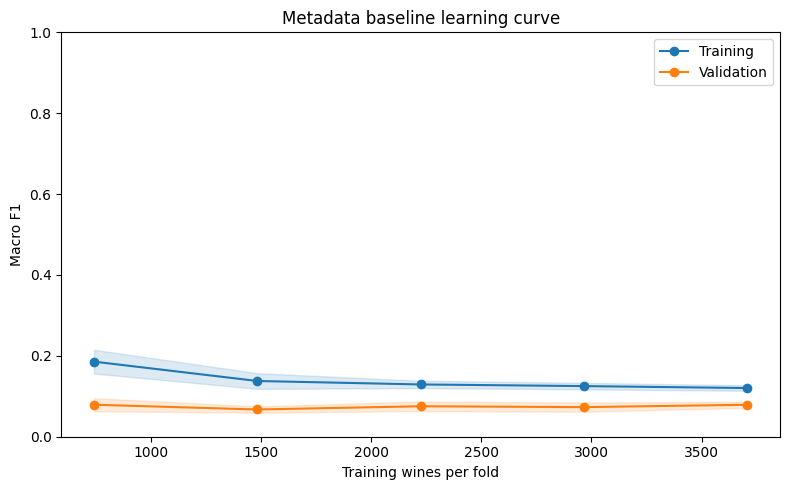

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
for label, values, color in [
    ("Training", curve_train, "tab:blue"),
    ("Validation", curve_validation, "tab:orange"),
]:
    mean = values.mean(axis=1)
    sd = values.std(axis=1, ddof=1)
    ax.plot(curve_sizes, mean, "o-", label=label, color=color)
    ax.fill_between(curve_sizes, np.clip(mean - sd, 0, 1),
                    np.clip(mean + sd, 0, 1), alpha=0.15, color=color)
ax.set(xlabel="Training wines per fold", ylabel="Macro F1",
       title="Metadata baseline learning curve", ylim=(0, 1))
ax.legend()
plt.tight_layout()
plt.show()

### Reading the expanded baseline diagnostics

Use the newly generated training/validation scores and learning curve above. The earlier four-year numerical conclusions do not apply automatically to eleven classes. Low scores on both partitions suggest limited metadata signal; a large gap suggests overfitting. A smaller gap alone is not evidence of better prediction.

## Add descriptions: regularized vintage classifier

Keep the established metadata baseline unchanged. Add TF-IDF description features to variety and subregion, using the exact same training/test wines and vintage classes. Remove explicit four-digit years from descriptions so the model cannot simply copy them.

TF-IDF turns words into numerical weights. Logistic regression uses L2 regularization; smaller `C` means stronger regularization. Tune `C` on five stratified folds of training data only, refitting TF-IDF and metadata encoding inside every fold. Select by validation macro F1, not by the smallest training–validation gap. The text-only notebook's best C need not be best for this combined model.

The test set has already been viewed, so these comparisons remain exploratory. Do not tune to test scores. Review language may reflect reviewer or variety differences; accuracy does not establish a causal vintage effect.

In [13]:
import re
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Add text by index; preserve the baseline split and targets exactly.
X_train_description = X_train.copy()
X_test_description = X_test.copy()
for frame in [X_train_description, X_test_description]:
    frame["description"] = wine_df.loc[frame.index, "description"].fillna("")

assert set(X_train_description.description.str.strip().str.lower()).isdisjoint(
    set(X_test_description.description.str.strip().str.lower())
)

def clean_vintage_description(text):
    return re.sub(r"\b(?:18|19|20|21)\d{2}\b", " ", text).lower()

combined_vintage_pipeline = Pipeline([
    ("features", ColumnTransformer([
        ("text", TfidfVectorizer(
            preprocessor=clean_vintage_description, lowercase=False,
            min_df=3, max_features=5000, ngram_range=(1, 1)
        ), "description"),
        ("metadata", OneHotEncoder(handle_unknown="ignore"), ["variety", "region_1"]),
    ])),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
])
combined_search = GridSearchCV(
    combined_vintage_pipeline,
    param_grid={"classifier__C": [0.01, 0.03, 0.1, 0.3, 1.0]},
    scoring={"accuracy": "accuracy", "macro_f1": "f1_macro"},
    refit="macro_f1",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    return_train_score=True, error_score="raise"
)
combined_search.fit(X_train_description, y_train)
combined_cv = pd.DataFrame(combined_search.cv_results_)
combined_regularization_results = pd.DataFrame({
    "C": combined_cv["param_classifier__C"].astype(float),
    "Train macro F1": combined_cv["mean_train_macro_f1"],
    "Validation macro F1": combined_cv["mean_test_macro_f1"],
    "Validation F1 SD": combined_cv["std_test_macro_f1"],
    "Validation accuracy": combined_cv["mean_test_accuracy"],
})
combined_regularization_results["F1 gap"] = (
    combined_regularization_results["Train macro F1"]
    - combined_regularization_results["Validation macro F1"]
)
print(combined_regularization_results.round(3).to_string(index=False))
print("\nSelected C:", combined_search.best_params_["classifier__C"])
# GridSearchCV refits the selected pipeline on the full training partition.
description_vintage_model = combined_search.best_estimator_

   C  Train macro F1  Validation macro F1  Validation F1 SD  Validation accuracy  F1 gap
0.01           0.051                0.042             0.002                0.157   0.009
0.03           0.115                0.086             0.006                0.206   0.029
0.10           0.228                0.146             0.008                0.270   0.082
0.30           0.429                0.199             0.013                0.300   0.230
1.00           0.710                0.257             0.008                0.325   0.453

Selected C: 1.0


                                         Test accuracy  Test macro F1
Model                                                                
Established metadata baseline                    0.152          0.084
Descriptions + metadata (CV-selected C)          0.345          0.285

Description + metadata per-vintage performance:
              precision    recall  f1-score   support

        2005       0.48      0.33      0.39        69
        2006       0.29      0.14      0.19        71
        2007       0.26      0.23      0.25        95
        2008       0.28      0.20      0.23       101
        2009       0.32      0.44      0.37       137
        2010       0.32      0.40      0.35       132
        2011       0.16      0.06      0.09        94
        2012       0.42      0.57      0.48       179
        2013       0.39      0.52      0.45       167
        2014       0.27      0.17      0.21        89
        2015       0.40      0.08      0.13        26

    accuracy         

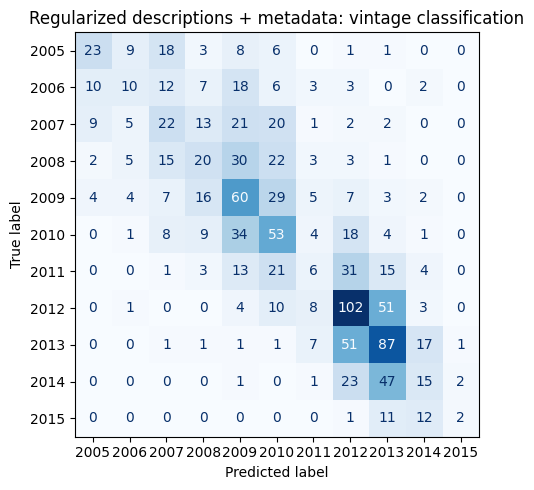

In [14]:
description_vintage_predictions = description_vintage_model.predict(X_test_description)
baseline_predictions = baseline_model.predict(X_test)
comparison = []
for name, predictions in [
    ("Established metadata baseline", baseline_predictions),
    ("Descriptions + metadata (CV-selected C)", description_vintage_predictions),
]:
    comparison.append({
        "Model": name,
        "Test accuracy": accuracy_score(y_test, predictions),
        "Test macro F1": f1_score(y_test, predictions, average="macro", zero_division=0),
    })
print(pd.DataFrame(comparison).set_index("Model").round(3).to_string())
print("\nDescription + metadata per-vintage performance:")
print(classification_report(y_test, description_vintage_predictions,
                            labels=selected_vintages, zero_division=0))
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, description_vintage_predictions, labels=selected_vintages,
    cmap="Blues", colorbar=False, ax=ax
)
ax.set_title("Regularized descriptions + metadata: vintage classification")
plt.tight_layout()
plt.show()

## Eyeball error analysis: 2005–2015 vintage model

**Purpose:** read incorrect predictions to generate specific hypotheses before changing the model again. Analyze the description + metadata logistic regression model already in this notebook, using its selected `C` and TF-IDF settings. This is not the separate SVM experimental candidate.

Use five out-of-fold predictions on the training partition: each review is predicted by a freshly fitted pipeline that did not train on that review. Do not inspect additional test reviews. Because `C` was previously selected on these training folds, these are exploratory errors, not an independent final estimate.

Show per-year errors, common actual→predicted confusions, two reproducibly sampled mistakes per actual year, and a few correct examples for context. Display full review text. Titles identify wines but are not model inputs. Model probabilities below are uncalibrated and should not be treated as reliable confidence estimates.

The review sheet now covers eleven years, sampling up to two errors per actual year (up to 22 errors). It is balanced for inspection, not a representative sample of error frequencies.

In [15]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold

error_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
error_predictions = pd.Series(index=y_train.index, dtype="int64")
error_probabilities = pd.Series(index=y_train.index, dtype=float)
for fit_positions, validation_positions in error_cv.split(X_train_description, y_train):
    fold_model = clone(description_vintage_model)
    fold_model.fit(X_train_description.iloc[fit_positions], y_train.iloc[fit_positions])
    fold_X = X_train_description.iloc[validation_positions]
    error_predictions.loc[fold_X.index] = fold_model.predict(fold_X)
    error_probabilities.loc[fold_X.index] = fold_model.predict_proba(fold_X).max(axis=1)

error_analysis = wine_df.loc[X_train_description.index,
    ["title", "description", "variety", "region_1", "taster_name"]].copy()
error_analysis["Actual vintage"] = y_train.astype(int)
error_analysis["Predicted vintage"] = error_predictions.astype(int)
error_analysis["Predicted class probability"] = error_probabilities
error_analysis["Correct"] = error_analysis["Actual vintage"].eq(error_analysis["Predicted vintage"])
error_analysis["Review word count"] = error_analysis.description.fillna("").str.split().str.len()
error_analysis["Contains year"] = error_analysis.description.fillna("").str.contains(
    r"\b(?:18|19|20|21)\d{2}\b", regex=True
)

print("Training-only out-of-fold error summary:")
per_year_errors = error_analysis.groupby("Actual vintage").Correct.agg(Reviews="size", Accuracy="mean")
per_year_errors["Error rate"] = 1 - per_year_errors.Accuracy
print(per_year_errors.round(3).to_string())
misclassified = error_analysis.loc[~error_analysis.Correct].copy()
confusion_counts = misclassified.groupby(["Actual vintage", "Predicted vintage"]).size().sort_values(ascending=False)
print("\nMost common confusions:")
print(confusion_counts.to_string())
print(f"\nTotal errors: {len(misclassified):,} / {len(error_analysis):,}")
print("Year mentions are removed before TF-IDF; raw text below retains them for inspection.")

Training-only out-of-fold error summary:
                Reviews  Accuracy  Error rate
Actual vintage                               
2005                275     0.255       0.745
2006                284     0.123       0.877
2007                381     0.255       0.745
2008                404     0.153       0.847
2009                546     0.408       0.592
2010                527     0.338       0.662
2011                375     0.064       0.936
2012                714     0.511       0.489
2013                667     0.562       0.438
2014                357     0.210       0.790
2015                105     0.010       0.990

Most common confusions:
Actual vintage  Predicted vintage
2012            2013                 224
2013            2012                 219
2014            2013                 192
2011            2012                 159
2008            2009                 152
2010            2009                 149
2009            2010                 128
2007           

### Read a small, reproducible sample

For each example ask: Is the language generic? Are variety or subregion clues stronger than vintage clues? Is there a reference to drinking windows or maturity? Does the review make the true year impossible to identify without outside information?

Sample two errors per actual year using a fixed seed. This intentionally covers each year rather than estimating the overall frequency of error types. Do not infer causes from a handful of examples. Read the correct examples too; a vivid description need not be vintage-specific.

In [16]:
sample_parts = []
for year in selected_vintages:
    group = misclassified.loc[misclassified["Actual vintage"].eq(year)]
    if not group.empty:
        sample_parts.append(group.sample(n=min(2, len(group)), random_state=42))
eyeball_sample = pd.concat(sample_parts).copy()
for number, (source_row, row) in enumerate(eyeball_sample.iterrows(), 1):
    print(f"\nERROR {number} | source row {source_row} | actual {row['Actual vintage']} → predicted {row['Predicted vintage']}")
    print(f"{row['title']} | {row['variety']} | {row['region_1']} | reviewer: {row['taster_name']}")
    print(f"Predicted class probability (uncalibrated): {row['Predicted class probability']:.2f}")
    print(row.description)

correct_sample = error_analysis.loc[error_analysis.Correct].sample(n=3, random_state=42)
print("\nCORRECT EXAMPLES FOR CONTRAST")
for source_row, row in correct_sample.iterrows():
    print(f"\nSource row {source_row} | actual/predicted {row['Actual vintage']} | {row['title']}")
    print(row.description)

# A review sheet for the team to annotate manually; no labels are guessed by code.
eyeball_review_sheet = eyeball_sample.copy()
for column in ["Generic language?", "Variety/subregion clue?", "Maturity/drinking-window clue?",
               "Possible reviewer-style clue?", "Team notes"]:
    eyeball_review_sheet[column] = ""
eyeball_review_sheet.to_csv("napa_eyeball_error_review_2005_2015.csv", index_label="Source row")
print("\nSaved napa_eyeball_error_review_2005_2015.csv for manual team annotations.")


ERROR 1 | source row 71497 | actual 2005 → predicted 2009
Amicus by X Winery 2005 Cabernet Sauvignon (Spring Mountain District) | Cabernet Sauvignon | Spring Mountain District | reviewer: nan
Predicted class probability (uncalibrated): 0.27
Made from 100% Cabernet, this wine is very soft and somewhat sweet in pie-filling blackberry, cherry, chocolate and spice flavors. Drink now.

ERROR 2 | source row 50805 | actual 2005 → predicted 2007
Harlan Estate 2005 Red (Napa Valley) | Bordeaux-style Red Blend | Napa Valley | reviewer: nan
Predicted class probability (uncalibrated): 0.25
Smells a bit minty and peppery, but once in the mouth, turns ultra-generous in black currant, chocolate-covered mint and spicy cedar flavors. Massive, yet refined and elegant, and even with the firm tannins, grows more charming as it warms in the glass. Very fine quality, and likely to hold for many years.

ERROR 3 | source row 45143 | actual 2006 → predicted 2009
William Knuttel 2006 Trio Vineyard Cabernet Sau

### Check whether impressions hold beyond the sample

Summarize all development errors by common varieties and reviewers (at least 30 reviews). Group differences can reflect vintage mix and sample size, not necessarily bias caused by that group. Review length and year mentions are descriptive checks, not evidence that changing those features will improve the model.

In [17]:
for column in ["variety", "taster_name"]:
    group_summary = error_analysis.assign(Group=error_analysis[column].fillna("Unknown"))
    group_summary = group_summary.groupby("Group").Correct.agg(Reviews="size", Accuracy="mean")
    group_summary["Error rate"] = 1 - group_summary.Accuracy
    print(f"\n{column}: groups with at least 30 reviews")
    print(group_summary.loc[group_summary.Reviews >= 30].sort_values("Error rate", ascending=False).round(3).to_string())
print("\nAverage review length:")
print(error_analysis.groupby("Correct")["Review word count"].agg(["size", "mean", "median"]).round(1).to_string())
print("\nAccuracy by explicit year mention in raw review (removed before modeling):")
print(error_analysis.groupby("Contains year").Correct.agg(Reviews="size", Accuracy="mean").round(3).to_string())

error_analysis.to_csv("napa_oof_predictions_2005_2015.csv", index_label="Source row")
print("Saved all development OOF predictions to napa_oof_predictions_2005_2015.csv")


variety: groups with at least 30 reviews
                          Reviews  Accuracy  Error rate
Group                                                  
Rosé                           33     0.182       0.818
Sauvignon Blanc               309     0.265       0.735
Syrah                         107     0.280       0.720
Petite Sirah                   74     0.284       0.716
Meritage                       38     0.289       0.711
Merlot                        324     0.290       0.710
Chardonnay                    373     0.298       0.702
Zinfandel                     190     0.316       0.684
Red Blend                     219     0.320       0.680
Bordeaux-style Red Blend      292     0.329       0.671
Pinot Noir                     56     0.357       0.643
Cabernet Franc                 96     0.365       0.635
Cabernet Sauvignon           2196     0.368       0.632

taster_name: groups with at least 30 reviews
                Reviews  Accuracy  Error rate
Group                     

### Expanded-run findings and validity

The expanded dataset has **5,795 unique Napa wine titles** from 2005–2015: 4,635 training wines and 1,160 test wines. Every class supports the stratified split and five-fold CV. The original four-year train/test memberships were preserved. Both models and all diagnostics have been rerun; earlier four-year numerical claims were removed from this notebook.

The metadata baseline reaches test accuracy **15.2%** and macro F1 **0.084**. Adding descriptions reaches **34.5%** and **0.285** respectively. The majority-class reference accuracy is approximately **15.4%**. Description features remain useful, but the eleven-year task is harder; do not directly compare its raw accuracy with the previous four-year task.

The new eyeball sheet contains **22 development errors: two sampled per actual year**, with full review text and blank team annotation columns. The full development OOF export has 4,635 rows. The small balanced sample helps inspect all years but does not estimate overall error frequencies.

Class imbalance is important: 2015 has only 131 wines, compared with 893 in 2012. Its OOF recall is about **1%**, and 2011 recall about **6.4%**. Investigate these years and common adjacent-year confusions without dropping inconvenient classes based on results. Potential future training-only comparisons include class weighting; do not make claims of improvement until evaluated.

This expansion is valid as an exploratory robustness experiment, not independent final validation. The previously viewed four-year test subset remains part of the test partition, and repeated development choices must be disclosed. The model settings and CV tuning procedure were held consistent with the existing Project 3 description model; no new algorithm was introduced.